# Louvain communities: real networks vs null models

## 1. Load the data and the null models

In [1]:
# Real networks + their 20 null models
import time
from pathlib import Path

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from sklearn.metrics import normalized_mutual_info_score

NETWORKS = ['S1', 'S2', 'M1', 'M2', 'L1', 'L2']
ROOT = Path('.') if Path('data').exists() else Path('..')   # repository root
DATA = ROOT / 'data'
RESULTS = ROOT / 'results'
FIGS = RESULTS / 'figures'
FIGS.mkdir(parents=True, exist_ok=True)
NULL_DIR = DATA / 'null_models'
N_NULLS = 20


def load_network(name):
    '''Reads one company into an undirected graph without duplicates or self-loops.'''
    folder = DATA / f'{name}.csv'
    nodes = pd.read_csv(folder / 'nodes.csv', skipinitialspace=True)
    edges = pd.read_csv(folder / 'edges.csv', skipinitialspace=True)
    G = nx.Graph()
    G.add_nodes_from(nodes.iloc[:, 0])
    G.add_edges_from(zip(edges.iloc[:, 0], edges.iloc[:, 1]))
    G.remove_edges_from(list(nx.selfloop_edges(G)))
    return G


def null_graphs(name):
    '''Loads the null models of one network one at a time.'''
    for i in range(N_NULLS):
        yield nx.read_edgelist(NULL_DIR / f'{name}_null_{i:02d}.edgelist.gz', nodetype=int)


graphs = {name: load_network(name) for name in NETWORKS}

## 2. Communities in the real networks

In [2]:
# Louvain on each real network -> communities_<network>.csv and louvain_communities.csv
def louvain(G, seed=42):
    '''Louvain communities as a list of node sets, largest first.'''
    return sorted(nx.community.louvain_communities(G, seed=seed), key=len, reverse=True)


def labels(communities):
    '''Dict node -> community number (0 = largest).'''
    return {node: c for c, members in enumerate(communities) for node in members}


def community_stats(G, communities):
    '''Number and size of communities, modularity, share of edges between communities.'''
    lab = labels(communities)
    between = sum(lab[u] != lab[v] for u, v in G.edges())
    sizes = [len(c) for c in communities]
    return {
        'communities': len(communities),
        'largest community': max(sizes),
        'median community size': np.median(sizes),
        'modularity': nx.community.modularity(G, communities),
        'share of edges between communities': between / G.number_of_edges(),
    }


partitions, rows = {}, {}
for name, G in graphs.items():
    partitions[name] = louvain(G)
    rows[name] = community_stats(G, partitions[name])
    pd.DataFrame(list(labels(partitions[name]).items()), columns=['node', 'community']) \
        .to_csv(RESULTS / f'communities_{name}.csv', index=False)

real = pd.DataFrame.from_dict(rows, orient='index')
real.to_csv(RESULTS / 'louvain_communities.csv')
real.round(3)

,communities,largest community,median community size,modularity,share of edges between communities
S1,9,66,36.0,0.451,0.378
S2,6,53,27.0,0.502,0.256
M1,10,308,137.5,0.510,0.299
M2,13,445,278.0,0.552,0.360
L1,22,1200,98.0,0.757,0.095
L2,11,1420,341.0,0.612,0.224


## 3. Modularity: real network vs its 20 null models

In [3]:
# z = are the communities real? delta Q = how strong 
rows = {}
for name in NETWORKS:
    start = time.time()
    q_null = [nx.community.modularity(R, louvain(R)) for R in null_graphs(name)]
    q_real = real.loc[name, 'modularity']
    rows[name] = {
        'Q real': q_real,
        'Q null mean': np.mean(q_null),
        'Q null std': np.std(q_null),
        'z-score': (q_real - np.mean(q_null)) / np.std(q_null),
        'delta Q (real - null)': q_real - np.mean(q_null),
    }
    print(f'{name}: done ({time.time() - start:.0f} s)')

vs_null = pd.DataFrame.from_dict(rows, orient='index')
vs_null.to_csv(RESULTS / 'louvain_modularity_vs_null.csv')
vs_null.round(3)

S1: done (0 s)
S2: done (0 s)
M1: done (3 s)
M2: done (17 s)
L1: done (11 s)
L2: done (19 s)


,Q real,Q null mean,Q null std,z-score,delta Q (real - null)
S1,0.451,0.198,0.003,73.041,0.254
S2,0.502,0.264,0.006,41.558,0.238
M1,0.510,0.148,0.002,170.083,0.362
M2,0.552,0.125,0.001,348.424,0.427
L1,0.757,0.244,0.001,371.419,0.513
L2,0.612,0.140,0.002,259.162,0.472


## 4. Stability check

In [4]:
# 10 extra Louvain runs per network, compared with normalised mutual information (1 = identical communities)
def nmi(G, a, b):
    '''Normalised mutual information between two partitions of the same graph.'''
    la, lb = labels(a), labels(b)
    nodes = list(G.nodes())
    return normalized_mutual_info_score([la[n] for n in nodes], [lb[n] for n in nodes])


rows = {}
for name, G in graphs.items():
    runs = [louvain(G, seed=s) for s in range(10)]
    nmis = [nmi(G, partitions[name], r) for r in runs]
    mods = [nx.community.modularity(G, r) for r in runs]
    rows[name] = {
        'NMI mean': np.mean(nmis),
        'NMI min': np.min(nmis),
        'modularity min': np.min(mods),
        'modularity max': np.max(mods),
        'communities min': min(len(r) for r in runs),
        'communities max': max(len(r) for r in runs),
    }
    print(name, 'done')

stability = pd.DataFrame.from_dict(rows, orient='index')
stability.to_csv(RESULTS / 'louvain_stability.csv')
stability.round(3)

S1 done
S2 done
M1 done
M2 done
L1 done
L2 done


,NMI mean,NMI min,modularity min,modularity max,communities min,communities max
S1,0.839,0.741,0.436,0.454,8,10
S2,0.815,0.727,0.505,0.514,6,6
M1,0.835,0.771,0.500,0.512,9,12
M2,0.851,0.815,0.543,0.552,13,14
L1,0.935,0.912,0.756,0.758,17,22
L2,0.792,0.729,0.600,0.619,11,13


## 5. Figures

In [5]:
# Figures read the CSVs from parts 2-3. PNGs go to results/figures/
def load_partition(name):
    '''Communities of one network from results/communities_<name>.csv, largest first.'''
    df = pd.read_csv(RESULTS / f'communities_{name}.csv')
    return [set(group['node']) for _, group in df.groupby('community')]


def labels(communities):
    '''Dict node -> community number (0 = largest).'''
    return {node: c for c, members in enumerate(communities) for node in members}


parts = {name: load_partition(name) for name in NETWORKS}
vs_null = pd.read_csv(RESULTS / 'louvain_modularity_vs_null.csv', index_col=0)

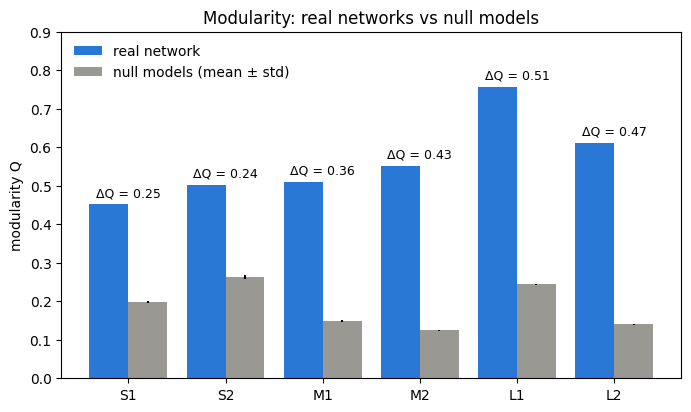

In [6]:
# 5a. Main result: modularity of the real network vs its null models
x = np.arange(len(NETWORKS))
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(x - 0.2, vs_null['Q real'], width=0.4, color='#2a78d6', label='real network')
ax.bar(x + 0.2, vs_null['Q null mean'], width=0.4, yerr=vs_null['Q null std'], color='#9a9893',
       label='null models (mean ± std)')
for i, name in enumerate(NETWORKS):
    dq = vs_null.loc[name, 'delta Q (real - null)']
    ax.text(i, vs_null.loc[name, 'Q real'] + 0.02, f'ΔQ = {dq:.2f}', ha='center', fontsize=9)
ax.set_xticks(x, NETWORKS)
ax.set_ylabel('modularity Q')
ax.set_ylim(0, 0.9)
ax.set_title('Modularity: real networks vs null models')
ax.legend(frameon=False)
fig.savefig(FIGS / 'modularity_real_vs_null.png', dpi=200, bbox_inches='tight')
plt.show()

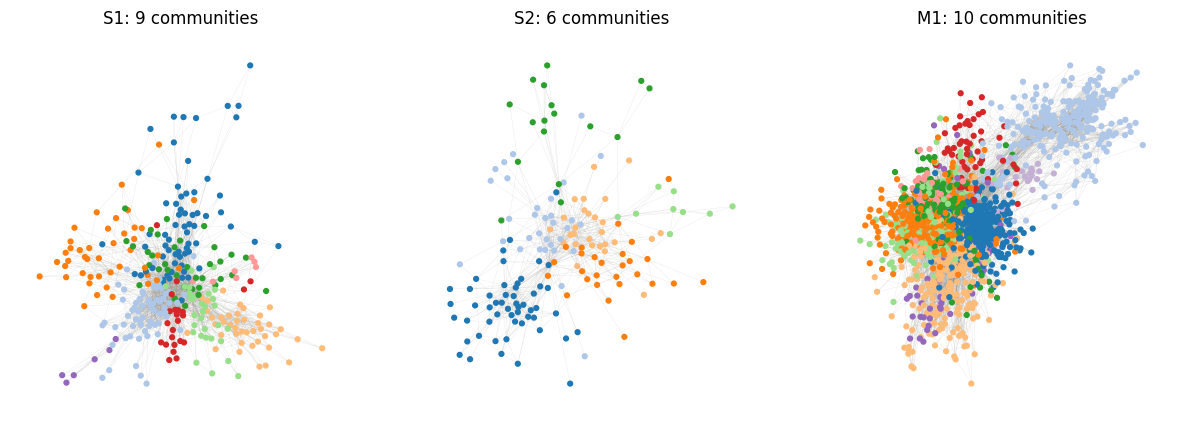

In [7]:
# 5b. Community map of the small networks: nodes coloured by community
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, name in zip(axes, ['S1', 'S2', 'M1']):
    G = graphs[name]
    lab = labels(parts[name])
    pos = nx.spring_layout(G, seed=42)
    nx.draw_networkx_edges(G, pos, ax=ax, edge_color='#9a9893', width=0.2, alpha=0.3)
    nx.draw_networkx_nodes(G, pos, ax=ax, node_size=12, node_color=[plt.cm.tab20(lab[n] % 20) for n in G])
    ax.set_title(f'{name}: {len(parts[name])} communities')
    ax.set_axis_off()
fig.savefig(FIGS / 'community_maps_small.png', dpi=200, bbox_inches='tight')
plt.show()

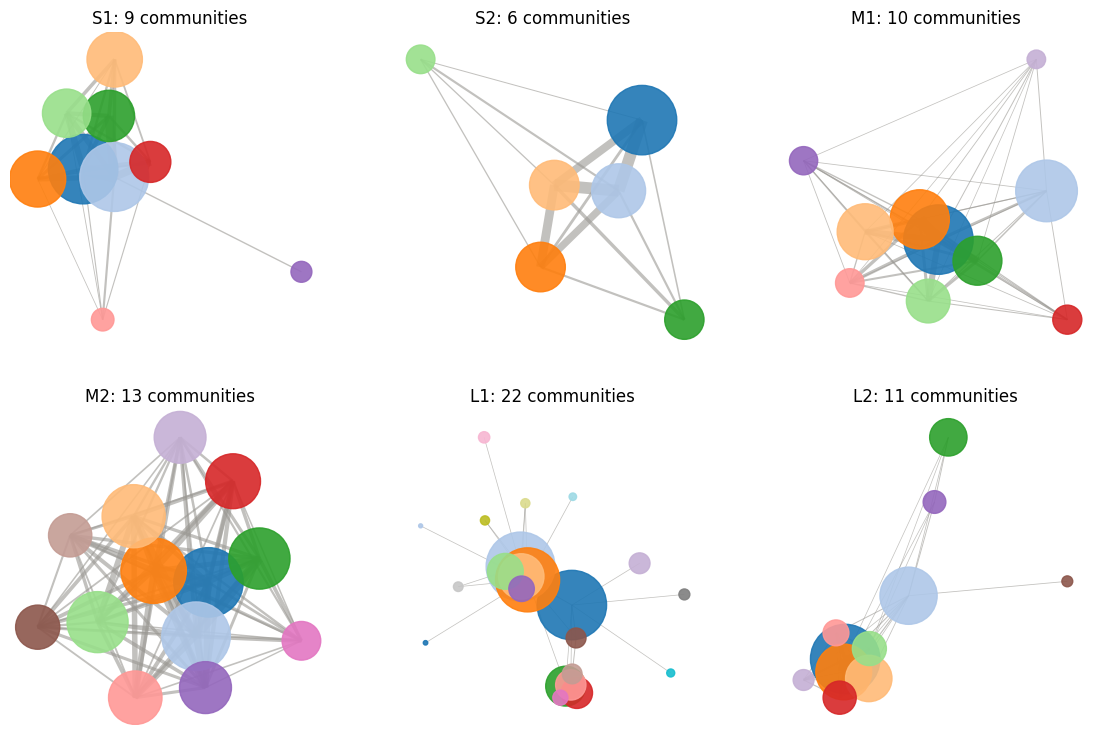

In [8]:
# 5c. Community graph of all six: circle = community (size = people), line width = friendships between them
def community_graph(G, communities):
    '''One node per community, edge weight = number of friendships between two communities.'''
    lab = labels(communities)
    C = nx.Graph()
    for c, members in enumerate(communities):
        C.add_node(c, size=len(members))
    for u, v in G.edges():
        a, b = lab[u], lab[v]
        if a != b:
            w = C.get_edge_data(a, b, {'weight': 0})['weight']
            C.add_edge(a, b, weight=w + 1)
    return C


fig, axes = plt.subplots(2, 3, figsize=(14, 9))
for ax, name in zip(axes.flat, NETWORKS):
    C = community_graph(graphs[name], parts[name])
    pos = nx.spring_layout(C, weight='weight', seed=42)
    sizes = np.array([C.nodes[c]['size'] for c in C])
    weights = np.array([C[a][b]['weight'] for a, b in C.edges()])
    nx.draw_networkx_edges(C, pos, ax=ax, width=0.5 + 8 * weights / weights.max(), edge_color='#9a9893', alpha=0.6)
    nx.draw_networkx_nodes(C, pos, ax=ax, node_size=2500 * sizes / sizes.max(),
                           node_color=[plt.cm.tab20(c % 20) for c in C], alpha=0.9)
    ax.set_title(f'{name}: {len(parts[name])} communities')
    ax.set_axis_off()
fig.savefig(FIGS / 'community_graphs.png', dpi=200, bbox_inches='tight')
plt.show()

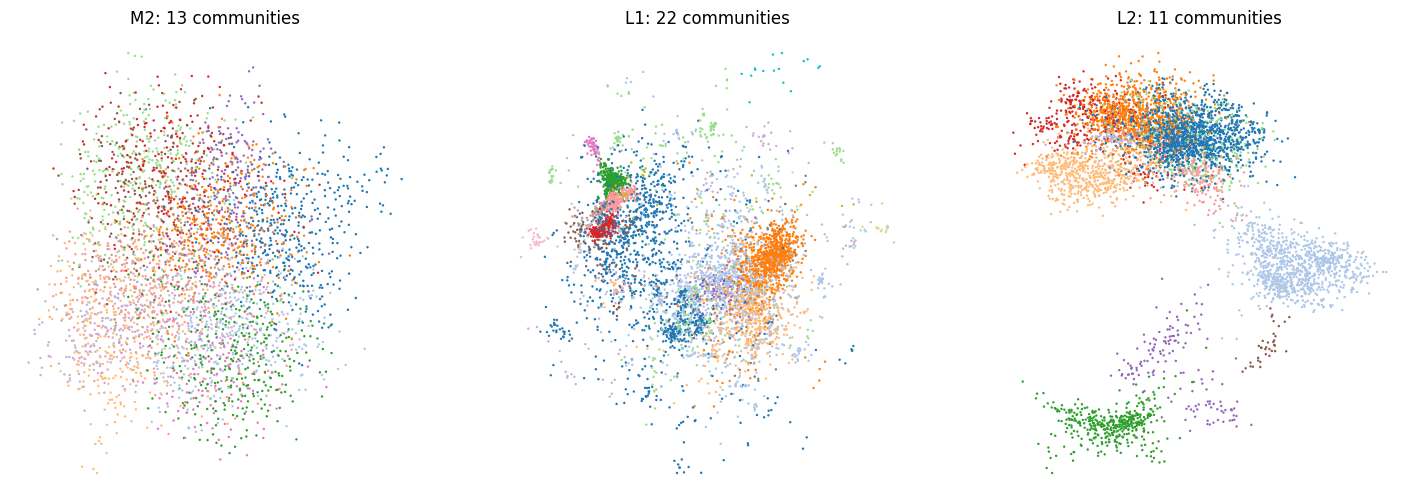

In [9]:
# 5d. Community map of the large networks, we kept edges left out to keep it readable
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, name in zip(axes, ['M2', 'L1', 'L2']):
    G = graphs[name]
    lab = labels(parts[name])
    pos = nx.spring_layout(G, seed=42, iterations=50)
    nx.draw_networkx_nodes(G, pos, ax=ax, node_size=3, linewidths=0,
                           node_color=[plt.cm.tab20(lab[n] % 20) for n in G])
    ax.set_title(f'{name}: {len(parts[name])} communities')
    ax.set_axis_off()
fig.savefig(FIGS / 'community_maps_large.png', dpi=200, bbox_inches='tight')
plt.show()